<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

# Synthetic Financial Time Series

**WGAN-GP: Wasserstein Training with Gradient Penalty (PyTorch)**

&copy; Dr. Yves J. Hilpisch

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>

## Imports & Settings

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pylab import plt, mpl

In [2]:
import torch

In [3]:
sys.path.insert(0, os.path.abspath('..'))
from synthts.data import load_eod, compute_log_returns, ReturnScaler
from synthts.wgangp import (WGANGenerator, Critic,
    train_wgangp, generate_samples)
from synthts.evaluate import (ks_test, ks_test_batch, pass_rate,
    describe_comparison, mse_sorted,
    plot_histograms, plot_sorted,
    plot_cumulative, plot_pvalue_histogram)

In [4]:
plt.style.use('seaborn-v0_8')
#mpl.rcParams['figure.dpi'] = 300
#mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.family'] = 'serif'

## Simple Example — Cubic Function

In [5]:
x = np.linspace(-2, 2, 500)
y = x ** 3
scaler = ReturnScaler()
y_ = scaler.fit_transform(y)

In [6]:
g = WGANGenerator(latent_dim=2, hidden_units=32, output_dim=1)
c = Critic(input_dim=1, hidden_units=32)

In [7]:
%%time
history = train_wgangp(
    g, c, y_.reshape(-1, 1),
    epochs=10001, batch_size=64,
    n_critic=1, lr_g=0.0001, lr_c=0.001,
    latent_dim=2, seed=100
)

Epoch     0 | D_real: 0.7146 D_fake: 0.6820 G: 0.6892
Epoch  2000 | D_real: 0.6940 D_fake: 0.6931 G: 0.6937
Epoch  4000 | D_real: 0.6937 D_fake: 0.6941 G: 0.6912
Epoch  6000 | D_real: 0.6925 D_fake: 0.6939 G: 0.6936
Epoch  8000 | D_real: 0.6921 D_fake: 0.6950 G: 0.6925
Epoch 10000 | D_real: 0.6955 D_fake: 0.6920 G: 0.6928
CPU times: user 16 s, sys: 4.43 s, total: 20.5 s
Wall time: 19.1 s


### Evaluation

In [8]:
data = pd.DataFrame({'real': y}, index=x)
N = 5
for i in range(N):
    samples = generate_samples(g, len(y), latent_dim=2)
    data[f'synth_{i:02d}'] = scaler.inverse_transform(samples)

In [9]:
data.describe().round(3)

,real,synth_00,synth_01,synth_02,synth_03,synth_04
count,500.000,500.000,500.000,500.000,500.000,500.000
mean,-0.000,0.106,0.187,0.057,0.040,0.049
std,3.045,3.046,3.043,2.843,3.082,2.991
min,-8.000,-7.474,-7.470,-7.360,-7.495,-7.243
25%,-1.000,-0.957,-0.826,-0.901,-0.978,-0.817
50%,-0.000,-0.116,-0.162,-0.118,-0.118,-0.109
75%,1.000,1.138,1.142,0.936,0.958,0.936
max,8.000,7.614,7.867,7.510,7.950,7.698


In [10]:
mse_sorted(data['real'].values, data['synth_00'].values)

np.float64(0.0900093401254851)

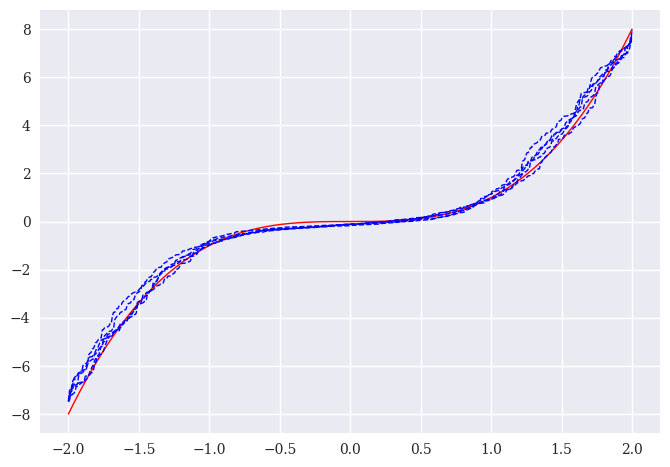

In [11]:
data.apply(np.sort).plot(
    style=['r'] + N * ['b--'], lw=1, legend=False);

## Financial Example — GLD Log-Returns

In [12]:
prices = load_eod(symbol='GLD', n_obs=2 * 252)
rets = compute_log_returns(prices)
scaler = ReturnScaler()
rets_ = scaler.fit_transform(rets)

In [13]:
g = WGANGenerator(latent_dim=2, hidden_units=32, output_dim=1)
c = Critic(input_dim=1, hidden_units=32)

In [14]:
%%time
history = train_wgangp(
    g, c, rets_.reshape(-1, 1),
    epochs=10001, batch_size=64,
    n_critic=1, lr_g=0.0001, lr_c=0.001,
    latent_dim=2, seed=100
)

Epoch     0 | D_real: 0.7434 D_fake: 0.6541 G: 0.7146
Epoch  2000 | D_real: 0.6922 D_fake: 0.6936 G: 0.6922
Epoch  4000 | D_real: 0.6936 D_fake: 0.6950 G: 0.6891
Epoch  6000 | D_real: 0.6890 D_fake: 0.6912 G: 0.6990
Epoch  8000 | D_real: 0.6858 D_fake: 0.7008 G: 0.6944
Epoch 10000 | D_real: 0.6915 D_fake: 0.6942 G: 0.6928
CPU times: user 15.8 s, sys: 4.39 s, total: 20.1 s
Wall time: 18.7 s


### Generating Synthetic Returns

In [15]:
data = pd.DataFrame({'real': rets})
N = 25
for i in range(N):
    samples = generate_samples(g, len(rets_), latent_dim=2)
    data[f'synth_{i:02d}'] = scaler.inverse_transform(samples)

In [16]:
describe_comparison(data, n_show=5)

,real,synth_00,synth_01,synth_02,synth_03
count,503.0000,503.0000,503.0000,503.0000,503.0000
mean,0.0014,0.0010,0.0007,0.0009,0.0009
std,0.0111,0.0081,0.0080,0.0075,0.0076
min,-0.0664,-0.0410,-0.0427,-0.0245,-0.0349
25%,-0.0044,-0.0033,-0.0036,-0.0029,-0.0038
50%,0.0018,0.0027,0.0017,0.0022,0.0020
75%,0.0082,0.0067,0.0060,0.0054,0.0061
max,0.0363,0.0174,0.0195,0.0192,0.0161


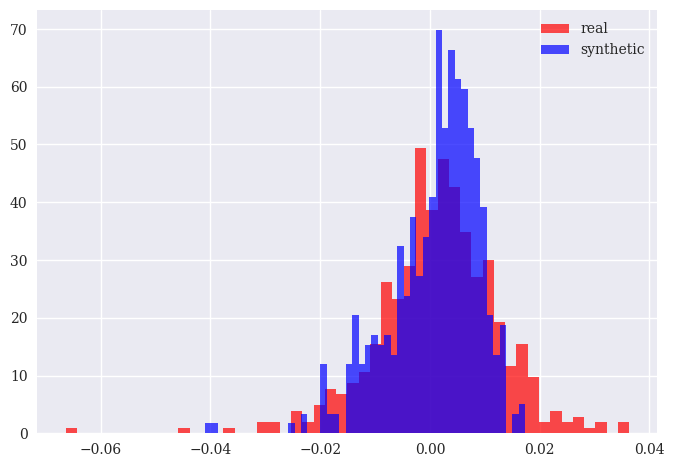

In [17]:
plot_histograms(data['real'].values, data['synth_00'].values);

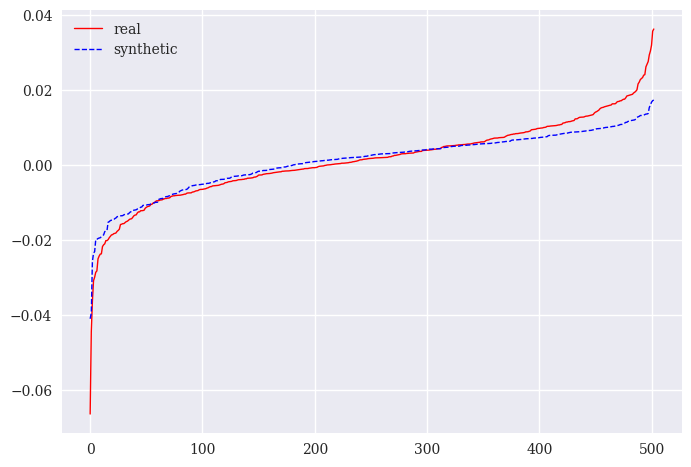

In [18]:
plot_sorted(data['real'].values, data['synth_00'].values);

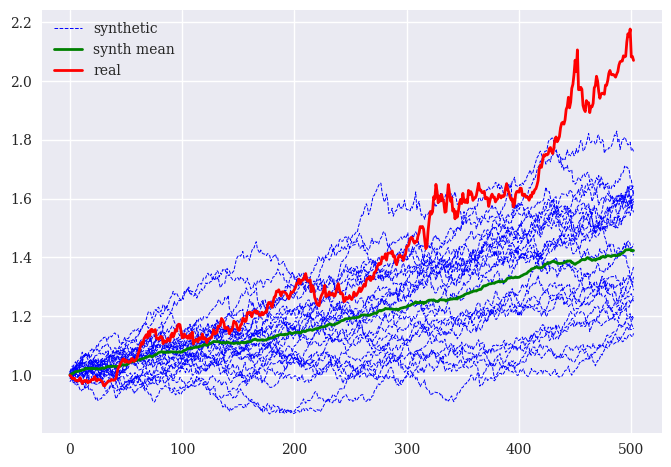

In [19]:
plot_cumulative(data, n_synth=N);

### Kolmogorov-Smirnov Test

In [20]:
synth_cols = [c for c in data.columns if c.startswith('synth')]
pvals = ks_test_batch(data['real'].values, data[synth_cols])
pvals.round(4)

array([0.0015, 0.0031, 0.0009, 0.0015, 0.002 , 0.0092, 0.0031, 0.0001,
       0.0092, 0.0015, 0.0012, 0.0002, 0.0092, 0.0031, 0.0002, 0.002 ,
       0.002 , 0.0015, 0.0247, 0.006 , 0.0012, 0.0031, 0.0002, 0.0004,
       0.0025])

In [21]:
f'KS pass rate: {pass_rate(pvals):.0%}'

'KS pass rate: 0%'

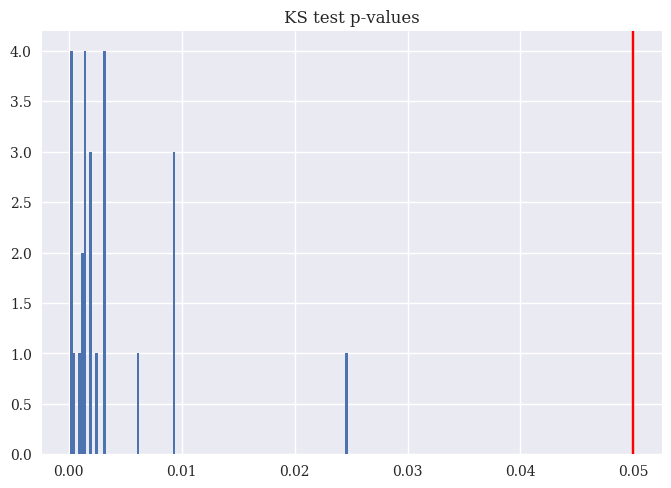

In [22]:
plot_pvalue_histogram(pvals);

<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>